In [6]:
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.arima.model import ARIMA
from datetime import datetime, timedelta
import numpy as np

In [7]:
df = pd.read_csv('../preprocess/parking_time_series_with_features_15min.csv', delimiter=',')

df['Time'] = pd.to_datetime(df['Time'])
df.set_index('Time', inplace=True)
df.sort_index(inplace=True)


In [8]:
end_date = datetime(2022, 1, 1)

train_data = df[df.index < end_date]
test_data = df[df.index >= end_date]

train_data.index = pd.DatetimeIndex(train_data.index.values, freq=train_data.index.inferred_freq)


In [ ]:
# Define ARIMA model parameters (p, d, q)
p = 3  
d = 1  
q = 2  

model = ARIMA(train_data['Parkings'], order=(p, d, q))
arima_results = model.fit()


                     Parkings  day_of_year  weekday  hour  is_holiday
2021-10-11 00:00:00         1          284        1     0           0
2021-10-11 00:15:00         1          284        1     0           0
2021-10-11 00:30:00         1          284        1     0           0
2021-10-11 00:45:00         1          284        1     0           0
2021-10-11 01:00:00         1          284        1     1           0
...                       ...          ...      ...   ...         ...
2021-12-31 22:45:00        79          365        5    22           0
2021-12-31 23:00:00        79          365        5    23           0
2021-12-31 23:15:00        79          365        5    23           0
2021-12-31 23:30:00        77          365        5    23           0
2021-12-31 23:45:00        79          365        5    23           0

[7872 rows x 5 columns]
                     Parkings  day_of_year  weekday  hour  is_holiday
Time                                                             

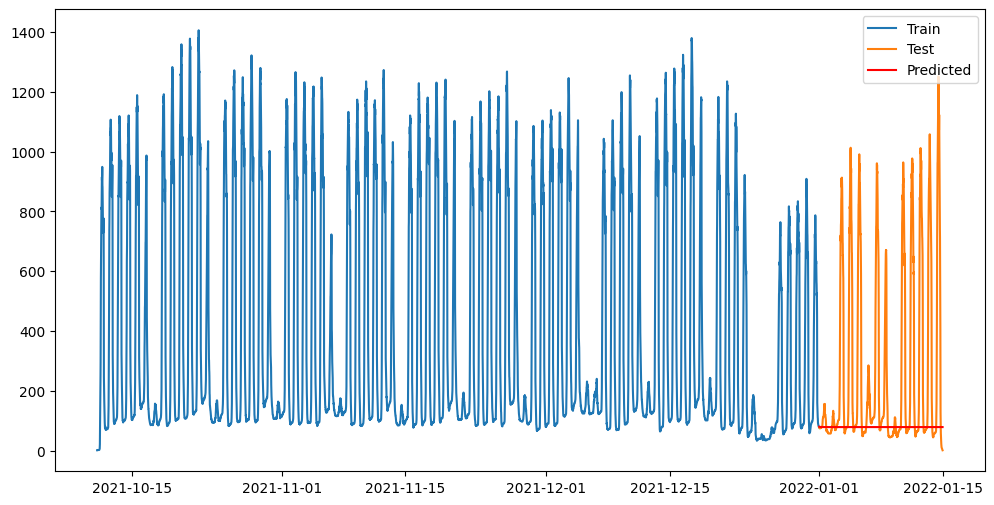

In [ ]:
# Predict using the fitted model
predictions = arima_results.predict(start=test_data.index[0], end=test_data.index[-1], dynamic=False)

print(train_data)
print(test_data)
print(predictions)

# Plot the actual vs predicted values
plt.figure(figsize=(12, 6))
plt.plot(train_data.index, train_data['Parkings'], label='Train')
plt.plot(test_data.index, test_data['Parkings'], label='Test')
plt.plot(test_data.index, predictions, label='Predicted', color='red')
plt.legend()
plt.show()
